Dataset loaded: e:\bikesh\UTA study\3rd Sem\ASDS 6304 OPTIMIZATION AND BIG DATA ANAL\final project\data\ercot_system_hourly_cleaned.csv
Dataset shape: (77496, 21)

Forecasting observations: 76032
Forecasting days: 3168

========== DATA SPLITS ==========
Training: 51552
Validation: 17256
Testing: 7224

========== RIDGE REGRESSION ==========
Alpha=0.1 | MAE=2307.95 MW | RMSE=3298.09 MW
Alpha=1 | MAE=2307.96 MW | RMSE=3298.11 MW
Alpha=10 | MAE=2308.06 MW | RMSE=3298.30 MW
Alpha=100 | MAE=2311.75 MW | RMSE=3302.40 MW
Alpha=1000 | MAE=2344.13 MW | RMSE=3329.41 MW

Best Ridge Alpha: 0.1

========== RBF-SVR ==========
SVR training samples: 6000
C=1 | Epsilon=0.01 | Gamma=scale | MAE=2349.57 MW | RMSE=3433.65 MW
C=1 | Epsilon=0.01 | Gamma=0.01 | MAE=2285.72 MW | RMSE=3300.28 MW
C=1 | Epsilon=0.1 | Gamma=scale | MAE=2364.40 MW | RMSE=3454.71 MW
C=1 | Epsilon=0.1 | Gamma=0.01 | MAE=2292.07 MW | RMSE=3296.50 MW
C=10 | Epsilon=0.01 | Gamma=scale | MAE=2581.82 MW | RMSE=3826.19 MW
C=10 | Epsilon=0.

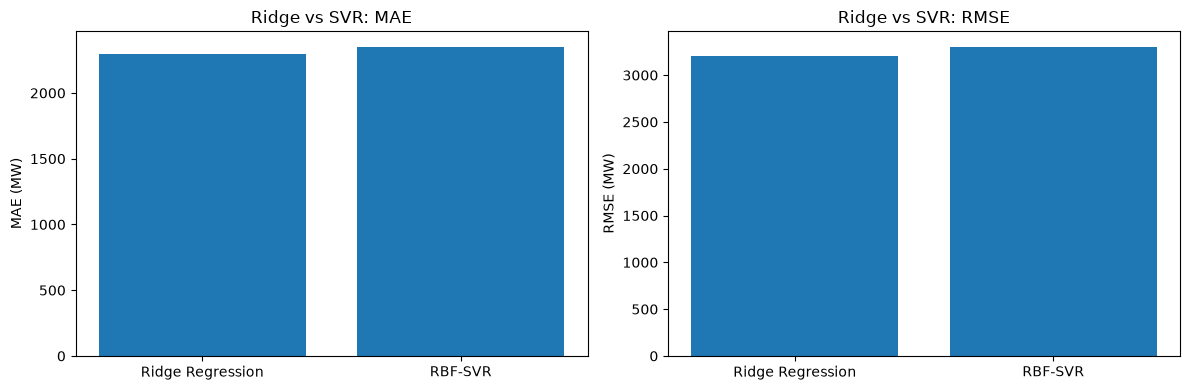

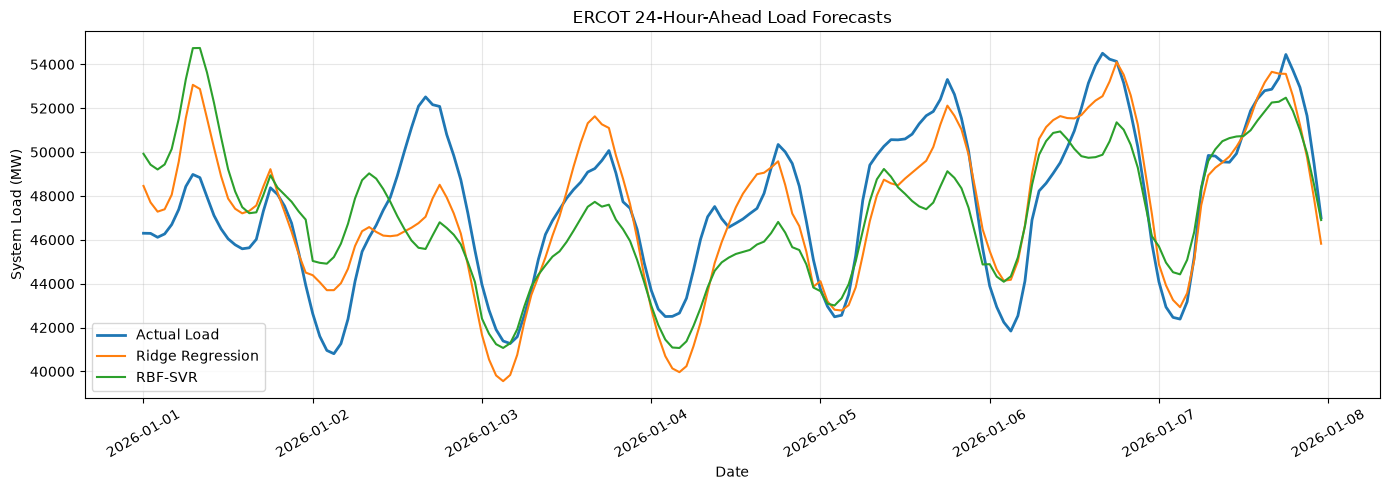

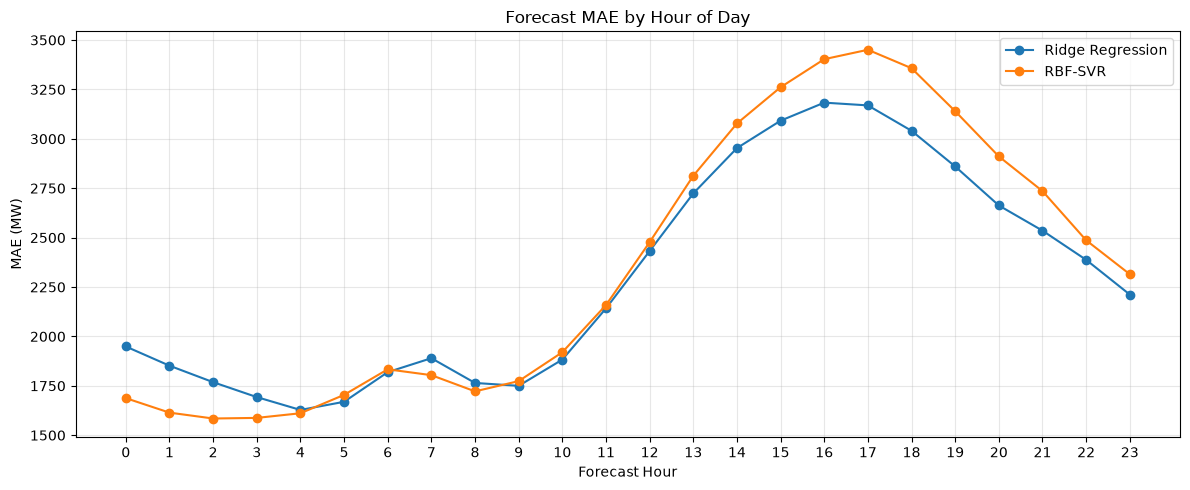


========== MODEL SUMMARY ==========
Best Ridge Alpha: 0.1
Best SVR Parameters: {'C': 10, 'epsilon': 0.1, 'gamma': 0.01}

Final Test Performance:
           Model      MAE_MW     RMSE_MW
Ridge Regression 2294.084907 3199.906507
         RBF-SVR 2351.173854 3302.769315

Forecast days: 301
Predictions per day: 24

Files exported successfully.
Ridge Regression and RBF-SVR completed.


In [1]:

# ============================================================
# ERCOT 24-HOUR-AHEAD ELECTRICITY LOAD FORECASTING
# RIDGE REGRESSION AND RBF SUPPORT VECTOR REGRESSION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import joblib
from pathlib import Path

from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterGrid

# ============================================================
# 1. LOAD ERCOT DATASET
# ============================================================

data_filename = "ercot_system_hourly_cleaned.csv"
data_candidates = (
    Path.cwd() / data_filename,
    Path.cwd() / "data" / data_filename,
    Path.cwd() / "final project" / "data" / data_filename,
)
DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {data_filename}. Start the kernel from the notebook's folder, "
        "the final project folder, or the workspace root."
    )

df = pd.read_csv(DATA_PATH)
OUT_DIR = DATA_PATH.parent

print("Dataset loaded:", DATA_PATH)
print("Dataset shape:", df.shape)

# ============================================================
# 2. CONSTRUCT DAY-AHEAD FORECASTING INPUTS
# ============================================================

# Convert timestamps and arrange observations chronologically
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# Identify each calendar day and hour
df["date"] = df["timestamp"].dt.normalize()
df["hour"] = df["timestamp"].dt.hour

# Retain days containing exactly 24 distinct hourly records
day_counts = df.groupby("date").agg(
    records=("hour", "size"),
    unique_hours=("hour", "nunique")
)

valid_days = day_counts.index[
    (day_counts["records"] == 24) &
    (day_counts["unique_hours"] == 24)
]

daily = df[df["date"].isin(valid_days)].pivot(
    index="date",
    columns="hour",
    values="system_total_mw"
).sort_index()

daily = daily.reindex(columns=range(24))

# Preserve the original calendar dates when finding historical days
daily_lookup = {
    date: daily.loc[date].to_numpy(dtype=float)
    for date in daily.index
}

# Construct forecasting examples using known historical loads
records = []

for target_date in daily.index:

    previous_day = target_date - pd.Timedelta(days=1)
    previous_week = target_date - pd.Timedelta(days=7)

    # Require complete historical demand for both reference days
    if (
        previous_day not in daily_lookup or
        previous_week not in daily_lookup
    ):
        continue

    yesterday_load = daily_lookup[previous_day]
    last_week_load = daily_lookup[previous_week]
    actual_load = daily_lookup[target_date]

    # Calculate summary statistics from the previous day
    yesterday_mean = np.mean(yesterday_load)
    yesterday_max = np.max(yesterday_load)
    yesterday_min = np.min(yesterday_load)

    # Create one prediction example for each next-day hour
    for hour in range(24):

        day_of_week = target_date.day_of_week
        month = target_date.month

        records.append({
            "timestamp": target_date + pd.Timedelta(hours=hour),
            "forecast_date": target_date,

            # Historical demand features
            "previous_day_same_hour": yesterday_load[hour],
            "previous_week_same_hour": last_week_load[hour],
            "previous_day_mean": yesterday_mean,
            "previous_day_max": yesterday_max,
            "previous_day_min": yesterday_min,

            # Calendar features
            "hour_sin": np.sin(2 * np.pi * hour / 24),
            "hour_cos": np.cos(2 * np.pi * hour / 24),
            "dow_sin": np.sin(2 * np.pi * day_of_week / 7),
            "dow_cos": np.cos(2 * np.pi * day_of_week / 7),
            "month_sin": np.sin(2 * np.pi * month / 12),
            "month_cos": np.cos(2 * np.pi * month / 12),
            "is_weekend": int(day_of_week >= 5),

            # Actual demand for evaluation
            "system_total_mw": actual_load[hour]
        })

model_df = pd.DataFrame(records)

print("\nForecasting observations:", len(model_df))
print("Forecasting days:", model_df["forecast_date"].nunique())

# ============================================================
# 3. DEFINE MODEL FEATURES AND TARGET
# ============================================================

FEATURES = [
    "previous_day_same_hour",
    "previous_week_same_hour",
    "previous_day_mean",
    "previous_day_max",
    "previous_day_min",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
    "is_weekend"
]

TARGET = "system_total_mw"

# ============================================================
# 4. CHRONOLOGICAL TRAIN, VALIDATION, AND TEST SPLITS
# ============================================================

# Training period: 2018-2023
train = model_df[
    model_df["forecast_date"] < "2024-01-01"
]

# Validation period: 2024-2025
val = model_df[
    (model_df["forecast_date"] >= "2024-01-01") &
    (model_df["forecast_date"] < "2026-01-01")
]

# Testing period: 2026 through available data
test = model_df[
    model_df["forecast_date"] >= "2026-01-01"
]

X_train = train[FEATURES]
y_train = train[TARGET]

X_val = val[FEATURES]
y_val = val[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

print("\n========== DATA SPLITS ==========")
print("Training:", len(train))
print("Validation:", len(val))
print("Testing:", len(test))

# ============================================================
# 5. MODEL EVALUATION FUNCTION
# ============================================================

# Calculate forecasting error in megawatts
def evaluate(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    return mae, rmse

# ============================================================
# 6. RIDGE REGRESSION
# ============================================================

print("\n========== RIDGE REGRESSION ==========")

ridge_alphas = [0.1, 1, 10, 100, 1000]

ridge_results = []
best_ridge = None
best_ridge_mae = float("inf")
best_alpha = None

# Train Ridge Regression using different alpha values
for alpha in ridge_alphas:

    ridge_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])

    start_time = time.time()

    ridge_model.fit(X_train, y_train)

    # Generate validation predictions
    val_predictions = ridge_model.predict(X_val)

    mae, rmse = evaluate(y_val, val_predictions)

    runtime = time.time() - start_time

    ridge_results.append({
        "Alpha": alpha,
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "Runtime_seconds": runtime
    })

    print(
        f"Alpha={alpha} | "
        f"MAE={mae:.2f} MW | "
        f"RMSE={rmse:.2f} MW"
    )

    # Select the lowest-validation-MAE model
    if mae < best_ridge_mae:
        best_ridge_mae = mae
        best_alpha = alpha
        best_ridge = ridge_model

print("\nBest Ridge Alpha:", best_alpha)

# ============================================================
# 7. RBF SUPPORT VECTOR REGRESSION
# ============================================================

print("\n========== RBF-SVR ==========")

# Select a computationally manageable training sample
MAX_SVR_SAMPLES = 6000

if len(X_train) > MAX_SVR_SAMPLES:

    sample_indices = np.linspace(
        0,
        len(X_train) - 1,
        MAX_SVR_SAMPLES,
        dtype=int
    )

    X_svr_train = X_train.iloc[sample_indices]
    y_svr_train = y_train.iloc[sample_indices]

else:
    X_svr_train = X_train
    y_svr_train = y_train

print("SVR training samples:", len(X_svr_train))

# Define RBF-SVR hyperparameter search
svr_parameters = {
    "C": [1, 10, 100],
    "epsilon": [0.01, 0.1],
    "gamma": ["scale", 0.01]
}

svr_results = []
best_svr = None
best_svr_mae = float("inf")
best_svr_params = None

# Train and evaluate each SVR configuration
for params in ParameterGrid(svr_parameters):

    svr_model = TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(
                kernel="rbf",
                C=params["C"],
                epsilon=params["epsilon"],
                gamma=params["gamma"],
                cache_size=500
            ))
        ]),
        transformer=StandardScaler()
    )

    start_time = time.time()

    svr_model.fit(X_svr_train, y_svr_train)

    # Generate validation predictions
    val_predictions = svr_model.predict(X_val)

    mae, rmse = evaluate(y_val, val_predictions)

    runtime = time.time() - start_time

    svr_results.append({
        **params,
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "Runtime_seconds": runtime
    })

    print(
        f"C={params['C']} | "
        f"Epsilon={params['epsilon']} | "
        f"Gamma={params['gamma']} | "
        f"MAE={mae:.2f} MW | "
        f"RMSE={rmse:.2f} MW"
    )

    # Select the lowest-validation-MAE model
    if mae < best_svr_mae:
        best_svr_mae = mae
        best_svr = svr_model
        best_svr_params = params

print("\nBest SVR Parameters:", best_svr_params)

# ============================================================
# 8. FINAL TEST EVALUATION
# ============================================================

print("\n========== FINAL TEST EVALUATION ==========")

# Generate test predictions
ridge_predictions = best_ridge.predict(X_test)
svr_predictions = best_svr.predict(X_test)

# Calculate test errors
ridge_mae, ridge_rmse = evaluate(
    y_test, ridge_predictions
)

svr_mae, svr_rmse = evaluate(
    y_test, svr_predictions
)

# Create model comparison table
results = pd.DataFrame({
    "Model": ["Ridge Regression", "RBF-SVR"],
    "MAE_MW": [ridge_mae, svr_mae],
    "RMSE_MW": [ridge_rmse, svr_rmse]
})

print(results.to_string(index=False))

# ============================================================
# 9. MODEL COMPARISON VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    results["Model"],
    results["MAE_MW"]
)

axes[0].set_title("Ridge vs SVR: MAE")
axes[0].set_ylabel("MAE (MW)")

axes[1].bar(
    results["Model"],
    results["RMSE_MW"]
)

axes[1].set_title("Ridge vs SVR: RMSE")
axes[1].set_ylabel("RMSE (MW)")

plt.tight_layout()
plt.show()

# ============================================================
# 10. ACTUAL VS PREDICTED LOAD
# ============================================================

# Display the first seven complete forecast days
n = min(168, len(test))

plt.figure(figsize=(14, 5))

plt.plot(
    test["timestamp"].iloc[:n],
    y_test.to_numpy()[:n],
    label="Actual Load",
    linewidth=2
)

plt.plot(
    test["timestamp"].iloc[:n],
    ridge_predictions[:n],
    label="Ridge Regression"
)

plt.plot(
    test["timestamp"].iloc[:n],
    svr_predictions[:n],
    label="RBF-SVR"
)

plt.title("ERCOT 24-Hour-Ahead Load Forecasts")
plt.xlabel("Date")
plt.ylabel("System Load (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# ============================================================
# 11. FORECAST ERROR BY HOUR
# ============================================================

hourly_results = pd.DataFrame({
    "Hour": test["timestamp"].dt.hour.to_numpy(),
    "Ridge_Error": np.abs(
        y_test.to_numpy() - ridge_predictions
    ),
    "SVR_Error": np.abs(
        y_test.to_numpy() - svr_predictions
    )
})

hourly_mae = hourly_results.groupby("Hour")[
    ["Ridge_Error", "SVR_Error"]
].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_mae.index,
    hourly_mae["Ridge_Error"],
    marker="o",
    label="Ridge Regression"
)

plt.plot(
    hourly_mae.index,
    hourly_mae["SVR_Error"],
    marker="o",
    label="RBF-SVR"
)

plt.title("Forecast MAE by Hour of Day")
plt.xlabel("Forecast Hour")
plt.ylabel("MAE (MW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 12. EXPORT FORECASTS
# ============================================================

forecast_output = pd.DataFrame({
    "timestamp": test["timestamp"].to_numpy(),
    "forecast_date": test["forecast_date"].to_numpy(),
    "actual_load_mw": y_test.to_numpy(),
    "ridge_forecast_mw": ridge_predictions,
    "svr_forecast_mw": svr_predictions
})

# Verify that every forecast day contains 24 predictions
daily_counts = forecast_output.groupby(
    "forecast_date"
).size()

assert (daily_counts == 24).all(), (
    "Each forecast day must contain 24 predictions."
)

# Save hourly forecasts
forecast_output.to_csv(
    OUT_DIR / "ercot_ml_24hour_forecasts.csv",
    index=False
)

# Save test evaluation metrics
results.to_csv(
    OUT_DIR / "ercot_ml_model_comparison.csv",
    index=False
)

# Save hyperparameter validation results
pd.DataFrame(ridge_results).to_csv(
    OUT_DIR / "ridge_validation_results.csv",
    index=False
)

pd.DataFrame(svr_results).to_csv(
    OUT_DIR / "svr_validation_results.csv",
    index=False
)

# Save trained machine learning models
joblib.dump(best_ridge, OUT_DIR / "ridge_model.pkl")
joblib.dump(best_svr, OUT_DIR / "svr_model.pkl")

# ============================================================
# 13. FINAL SUMMARY
# ============================================================

print("\n========== MODEL SUMMARY ==========")

print("Best Ridge Alpha:", best_alpha)
print("Best SVR Parameters:", best_svr_params)

print("\nFinal Test Performance:")
print(results.to_string(index=False))

print("\nForecast days:", len(daily_counts))
print("Predictions per day: 24")

print("\nFiles exported successfully.")
print("Ridge Regression and RBF-SVR completed.")
